# CAP5 · Assignment 5 · From molecule to candidate
**AI for Biology · Chapter 5 · Computational drug discovery**

| Part | Question | Tasks |
|---|---|---|
| 1 | What in this bioactivity table is actually measurable? | A |
| 2 | Does my model work on chemistry it has never seen? | B |
| 3 | Of a thousand catalogue compounds, which would you buy? | C |
| 4 | Would a chemist agree with the ten molecules you designed? | D |

- Complete each function as its docstring specifies. The check below it prints `[OK]`, `[x]` with a hint, or `[ ]` if not done.
- Your molecules are built from your student number. Answer each **Q** in the cell below it, using your numbers; answers are discussed in the oral. ⭐ = optional.
- Run the cells in order. Declare any AI assistant at the end. Colab, CPU only. About 2 hours.

In [10]:
STUDENT_NUMBER = "a2023235452"   # TODO: your student number, e.g. "a2024123456"
ATTEMPT = 1                      # increase it to get a new data set (your grade uses the attempt you submit)

In [11]:
#@title Install RDKit (run once per session, about 30 s)
%pip install -q rdkit
# optional, for the chemical language model row of Part 2:
# %pip install -q transformers torch

In [12]:
#@title Setup, your data and the helpers (run it; you do not need to read it)
# Builds your molecules from your student number; defines the helpers you will use, the checks and the grader.
import os, sys, json, time, hashlib, datetime, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from rdkit import Chem, RDLogger, RDConfig, DataStructs
from rdkit.Chem import Descriptors, Crippen, QED, rdMolDescriptors, rdFingerprintGenerator, BRICS, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, roc_auc_score, mean_absolute_error, roc_curve
warnings.filterwarnings("ignore"); RDLogger.DisableLog("rdApp.*")
sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score")); import sascorer
IN_COLAB = "google.colab" in sys.modules
DATA_DIR, RESULTS_DIR = Path("data"), Path("results")
DATA_DIR.mkdir(exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True})
BLUE, ORANGE, AQUA, GREY, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#8e5bd0"

# ------------------------------------------------------------------ the chemical series (one generative model for all parts)
_CORES = {
 "benzamide":      "O=C(N({r2}))c1ccccc1({r1})",
 "sulfonamide":    "O=S(=O)(N({r2}))c1ccccc1({r1})",
 "quinazoline":    "c1ccc2c(c1({r1}))ncnc2N({r2})",
 "pyrimidinamine": "Nc1nccc(n1)N({r2})c1ccccc1({r1})",
 "indole":         "c1ccc2c(c1({r1}))cc([nH]2)C(=O)N({r2})",
 "benzimidazole":  "c1ccc2c(c1({r1}))nc([nH]2)N({r2})",
 "pyrazole":       "c1cc(nn1({r2}))C(=O)Nc1ccccc1({r1})",
 "quinoline":      "c1ccc2c(c1({r1}))ccc(n2)N({r2})",
 "thiazole":       "c1csc(n1)Nc1ccc({r2})cc1({r1})",
 "oxadiazole":     "c1cc(ccc1({r1}))c1noc(n1)({r2})",
 "piperazinearyl": "C1CN(CCN1({r2}))c1ccccc1({r1})",
 "biarylurea":     "O=C(Nc1ccccc1({r1}))Nc1ccccc1({r2})",
 "pyridinecarbox": "O=C(N({r2}))c1cccnc1({r1})",
 "naphthamide":    "O=C(N({r2}))c1ccc2ccccc2c1({r1})"}
_R1 = ["", "Cl", "F", "Br", "OC", "C", "C(F)(F)F", "OC(F)(F)F", "C#N", "N", "O", "S(=O)(=O)N",
       "C(=O)O", "C(=O)N", "N7CCOCC7", "N7CCCC7", "OCC", "CC", "C(C)C", "[N+](=O)[O-]"]
_R2 = ["C", "CC", "CCC", "C(C)C", "C7CCCCC7", "C7CCCC7", "Cc7ccccc7", "c7ccccc7", "CCO",
       "CCN7CCOCC7", "CCN(C)C", "c7ccncc7", "Cc7ccc(F)cc7", "CC(=O)N", "C7CCNCC7", "CCCN7CCCC7",
       "c7ccc(Cl)cc7", "c7ccc(OC)cc7", "CC7CCCO7", "CCS(=O)(=O)C"]
_SAR = {"MolLogP": .55, "TPSA": -.30, "NumHDonors": -.25, "NumRotatableBonds": -.20,
        "HeavyAtoms": .35, "AromaticRings": .30, "FractionCSP3": -.15}     # transferable physicochemical SAR
# variance budget of the true pIC50: physicochemical trend, substituent effects, per-scaffold offset, assay noise
_F_TRANS, _F_SUB, _F_SCAF, _F_NOISE = .45, .30, .17, .08


def _enumerate(rng, cores, n):
    out, seen, tries = [], set(), 0
    while len(out) < n and tries < 60 * n:
        tries += 1
        c, r1, r2 = cores[rng.integers(len(cores))], _R1[rng.integers(len(_R1))], _R2[rng.integers(len(_R2))]
        s = _CORES[c].format(r1=r1, r2=r2).replace("()", "")
        m = Chem.MolFromSmiles(s)
        if m is None: continue
        s = Chem.MolToSmiles(m)
        if s in seen: continue
        seen.add(s); out.append((s, c, r1, r2))
    return pd.DataFrame(out, columns=["smiles", "core", "r1", "r2"])


def _hash01(s, salt):
    return (int(hashlib.sha256(f"{salt}|{s}".encode()).hexdigest(), 16) % 10**9) / 10**9


def _z(v):
    v = np.asarray(v, float)
    return (v - v.mean()) / v.std()


def _gauss_hash(keys, salt):
    u = np.array([_hash01(str(k), salt) for k in keys])
    return stats.norm.ppf(np.clip(u, 1e-4, 1 - 1e-4))


def _true_pic50(lib, scaffolds, desc, rng):
    """6.5 + a physicochemical trend + additive substituent effects + a per-scaffold offset + assay noise."""
    Z = (desc - desc.mean()) / desc.std(ddof=0)
    trans = _z(sum(w * Z[c].to_numpy() for c, w in _SAR.items()))
    sub = _z(_gauss_hash(lib.r1, 11) + _gauss_hash(lib.r2, 13))
    off = _z(_gauss_hash(scaffolds, 7))
    return (6.5 + np.sqrt(_F_TRANS) * trans + np.sqrt(_F_SUB) * sub + np.sqrt(_F_SCAF) * off
            + np.sqrt(_F_NOISE) * rng.normal(0, 1, len(lib))).round(3)


def _descriptors(smiles):
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        rows.append(dict(MolWt=Descriptors.MolWt(m), MolLogP=Crippen.MolLogP(m), TPSA=rdMolDescriptors.CalcTPSA(m),
                         NumHDonors=rdMolDescriptors.CalcNumHBD(m), NumHAcceptors=rdMolDescriptors.CalcNumHBA(m),
                         NumRotatableBonds=rdMolDescriptors.CalcNumRotatableBonds(m),
                         RingCount=rdMolDescriptors.CalcNumRings(m), AromaticRings=rdMolDescriptors.CalcNumAromaticRings(m),
                         FractionCSP3=rdMolDescriptors.CalcFractionCSP3(m), HeavyAtoms=float(m.GetNumHeavyAtoms()),
                         QED=QED.qed(m), SA=sascorer.calculateScore(m)))
    return pd.DataFrame(rows, index=list(smiles)).round(4)


_SALTS = [".Cl", ".[Na+]", ".O", ".OC(=O)C", ".OS(=O)(=O)O"]


def _write_bioactivity(rng, lib, y, out):
    """A ChEMBL-style table: mixed units, censored values, replicates, salts, a few unit errors and bad SMILES."""
    rows, n = [], len(lib)
    ic50_nM = 10 ** (9 - y)
    _n_ex = int(rng.integers(45, 80))                                # compounds with no usable record at all
    _ex = rng.choice(n, _n_ex, replace=False)
    _c, _u = int(round(_n_ex * 0.42)), int(round(_n_ex * 0.75))
    only_censored, only_units, only_broken = _ex[:_c], _ex[_c:_u], _ex[_u:]
    measured = np.setdiff1d(np.arange(n), _ex)
    for i in measured:
        reps = 1 + (rng.random() < 0.16) + (rng.random() < 0.05)
        for r in range(reps):
            v = ic50_nM[i] * np.exp(rng.normal(0, 0.12))
            unit = rng.choice(["nM", "uM", "M"], p=[.70, .25, .05])
            val = v / {"nM": 1, "uM": 1e3, "M": 1e9}[unit]
            if r > 0 and rng.random() < 0.12:                         # a replicate recorded in the wrong unit
                unit, val = ("nM", v / 1e3) if unit == "uM" else ("uM", v)
            smi = lib.smiles[i] + (_SALTS[rng.integers(len(_SALTS))] if rng.random() < 0.15 else "")
            rows.append((f"CHEMBL{100000 + i}", smi, "IC50", "=", float(f"{val:.4g}"), unit))
    for i in np.r_[only_censored, rng.choice(measured, 125, replace=False)]:
        rows.append((f"CHEMBL{100000 + i}", lib.smiles[i], "IC50", ">", 10000.0, "nM"))    # above the top concentration
    for i in rng.choice(measured, 70, replace=False):                 # a different endpoint
        rows.append((f"CHEMBL{100000 + i}", lib.smiles[i], rng.choice(["Ki", "EC50"]),
                     "=", float(f"{10 ** (9 - y[i] + rng.normal(0, .3)):.4g}"), "nM"))
    for i in np.r_[only_units, rng.choice(measured, 25, replace=False)]:                   # unusable units
        rows.append((f"CHEMBL{100000 + i}", lib.smiles[i], "IC50", "=", round(float(rng.uniform(1, 90)), 2),
                     rng.choice(["ug.mL-1", "%"])))
    for i in only_broken:                                             # SMILES that will not parse
        rows.append((f"CHEMBL{100000 + i}", lib.smiles[i][:-1] + "Q", "IC50", "=",
                     float(f"{10 ** (9 - y[i]):.4g}"), "nM"))
    raw = pd.DataFrame(rows, columns=["compound_id", "smiles", "standard_type", "standard_relation",
                                      "standard_value", "standard_units"])
    raw = raw.sample(frac=1, random_state=int(rng.integers(1e6))).reset_index(drop=True)
    raw.insert(0, "record_id", [f"ACT{i:05d}" for i in range(len(raw))])
    raw.to_csv(out / "bioactivity_raw.csv", index=False)
    return raw


def _write_screen(rng, pool, y_pool, desc_pool, out):
    """A purchasable catalogue with known actives spiked in, plus docking scores and co-folding predictions.

    Potency against THIS target is the compound's 2-D potency plus a hidden 3-D complementarity term: a
    ligand-based model cannot see that term, a structure-based method partly can.
    """
    hidden = rng.normal(0, 1, len(pool))
    y_t = y_pool + 1.45 * hidden                                            # potency against the screening target
    hi, lo = np.quantile(y_t, 0.82), np.quantile(y_t, 0.45)
    act = rng.choice(np.where(y_t >= hi)[0], 45, replace=False)
    cat = rng.choice(np.setdiff1d(np.where(y_t <= lo)[0], act), 950, replace=False)
    idx = np.concatenate([act, cat])
    z_mw = ((desc_pool.MolWt - desc_pool.MolWt.mean()) / desc_pool.MolWt.std()).to_numpy()[idx]
    score = -(5.2 + 0.30 * (y_t[idx] - y_t.mean()) + 0.80 * z_mw + rng.normal(0, 0.90, len(idx)))
    tab = pd.DataFrame({"compound_id": [f"ZID{i:05d}" for i in range(len(idx))],
                        "smiles": pool.smiles.to_numpy()[idx],
                        "source": ["known_active"] * len(act) + ["catalogue"] * len(cat),
                        "is_active": [1] * len(act) + [0] * len(cat),
                        "docking_score": score.round(2),
                        "_true": y_t[idx]})
    tab = tab.sample(frac=1, random_state=int(rng.integers(1e6))).reset_index(drop=True)
    tab.drop(columns="_true").to_csv(out / "screen_library.csv", index=False)
    sub = tab.nsmallest(80, "docking_score").copy()                         # co-folding is run on the docking shortlist
    sub["pred_pK_cofold"] = (6.0 + 0.55 * (sub._true.to_numpy() - y_t.mean())
                             + rng.normal(0, 1.00, len(sub))).round(2)
    sub["cofold_confidence"] = np.clip(rng.normal(0.78, 0.09, len(sub)), 0.4, 0.97).round(3)
    sub[["compound_id", "smiles", "pred_pK_cofold", "cofold_confidence"]].sort_values("compound_id").to_csv(
        out / "cofold_predictions.csv", index=False)
    return tab


def _write_admet(rng, pool, desc_pool, out, n=900):
    """Two simulated endpoints with the usual drivers: lipophilicity, size, polarity."""
    idx = rng.choice(len(pool), n, replace=False)
    d = desc_pool.iloc[idx]
    logS = (-0.72 * d.MolLogP - 0.0062 * d.MolWt - 0.33 * d.AromaticRings + 0.52
            + rng.normal(0, 0.55, n))
    p_herg = 1 / (1 + np.exp(-(-6.3 + 0.95 * d.MolLogP + 0.0075 * d.MolWt - 0.018 * d.TPSA)))
    pd.DataFrame({"smiles": pool.smiles.to_numpy()[idx], "logS": logS.round(3),
                  "herg_blocker": (rng.random(n) < p_herg).astype(int)}).to_csv(out / "admet_train.csv", index=False)


def _simulate_all(rng, out):
    cores = list(_CORES)
    rng.shuffle(cores)
    target_cores, cat_cores = cores[:10], cores[6:]
    lib = _enumerate(rng, target_cores, 1600)
    lib["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(s)) for s in lib.smiles]
    d_lib = _descriptors(lib.smiles)
    y_lib = _true_pic50(lib, lib.scaffold, d_lib, rng)
    raw = _write_bioactivity(rng, lib, y_lib, out)
    pool = _enumerate(rng, cat_cores, 2800)
    pool["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(s)) for s in pool.smiles]
    d_pool = _descriptors(pool.smiles)
    y_pool = _true_pic50(pool, pool.scaffold, d_pool, rng)
    screen = _write_screen(rng, pool, y_pool, d_pool, out)
    _write_admet(rng, pool, d_pool, out)
    return dict(n_compounds=len(lib), n_records=len(raw), n_screen=len(screen),
                truth=pd.Series(y_lib, index=lib.smiles.to_numpy()))


# ------------------------------------------------------------------ helpers you will use
def largest_fragment_smiles(smiles):
    """Canonical SMILES of the largest fragment (by heavy atoms) of `smiles`; None if it does not parse."""
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return None
    frags = Chem.GetMolFrags(m, asMols=True, sanitizeFrags=True)
    return Chem.MolToSmiles(max(frags, key=lambda f: f.GetNumHeavyAtoms()))


def murcko_scaffold(smiles):
    """Bemis-Murcko scaffold of `smiles` (ring systems and the linkers between them), as canonical SMILES."""
    m = Chem.MolFromSmiles(smiles)
    return None if m is None else MurckoScaffold.MurckoScaffoldSmiles(mol=m)


_FPG = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)


def ecfp4(smiles):
    """ECFP4 (Morgan radius 2, 2048 bits) as a 0/1 array, molecules x bits."""
    return np.array([_FPG.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles], dtype=float)


_DESC_CACHE = {}


def descriptors(smiles):
    """Twelve physicochemical descriptors per molecule, as a DataFrame indexed by SMILES. Values are cached, so
    asking for the same molecule twice costs nothing - the generators in Part 4 rely on that."""
    smiles = list(smiles)
    missing = [s for s in dict.fromkeys(smiles) if s not in _DESC_CACHE]
    if missing:
        d = _descriptors(missing)
        for s in missing:
            _DESC_CACHE[s] = d.loc[s]
    return pd.DataFrame([_DESC_CACHE[s] for s in smiles], index=smiles)


_TO_NM_ = {"nM": 1.0, "uM": 1e3, "M": 1e9}


def record_level_pIC50(raw):
    """The usable IC50 records, still one row per measurement, with a pIC50_record column: the same arithmetic as
    your `curate_activity` but without the aggregation, so you can see where a compound's replicates disagree."""
    t = raw[(raw.standard_type == "IC50") & (raw.standard_relation == "=")
            & raw.standard_units.isin(_TO_NM_) & (raw.standard_value > 0)].copy()
    t["canonical_smiles"] = [largest_fragment_smiles(s) for s in t.smiles]
    t = t[t.canonical_smiles.notna()]
    t["pIC50_record"] = 9 - np.log10(t.standard_value * t.standard_units.map(_TO_NM_))
    return t


def fit_qsar(X, y, seed=0):
    """Random forest regressor, 400 trees."""
    return RandomForestRegressor(400, random_state=seed, n_jobs=-1).fit(X, y)


def random_split(n, test_fraction=0.25, seed=0):
    """Indices (train, test) of a plain random split, for comparison with the scaffold split."""
    idx = np.random.default_rng(seed).permutation(n)
    cut = int(round((1 - test_fraction) * n))
    return np.sort(idx[:cut]), np.sort(idx[cut:])


def embed_clm(smiles, model_name="DeepChem/ChemBERTa-77M-MLM", batch=64):
    """Mean-pooled embeddings from a pretrained chemical language model. Needs `transformers` and network
    access; returns None (with a message) if either is missing, so the rest of the notebook still runs."""
    try:
        import torch
        from transformers import AutoTokenizer, AutoModel
        tok = AutoTokenizer.from_pretrained(model_name)
        mod = AutoModel.from_pretrained(model_name).eval()
    except Exception as e:
        print(f"  chemical language model not available ({type(e).__name__}): {e}")
        print("  install it with  %pip install transformers torch  and rerun; the comparison then gains a third row.")
        return None
    out = []
    with torch.no_grad():
        for i in range(0, len(smiles), batch):
            enc = tok(list(smiles[i:i + batch]), padding=True, truncation=True, max_length=128, return_tensors="pt")
            h = mod(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1).float()
            out.append(((h * mask).sum(1) / mask.sum(1)).numpy())
    return np.vstack(out)


def brics_fragments(smiles):
    """BRICS fragments (retrosynthetic bonds) of a set of molecules, as a list of SMILES with attachment points."""
    frags = set()
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        if m is not None:
            frags |= set(BRICS.BRICSDecompose(m))
    return sorted(frags)


def brics_sample(fragments, n, seed=0, min_atoms=10, max_atoms=40, max_tries=40000):
    """Recombine BRICS fragments into new molecules. Every product is a valid molecule by construction."""
    import random
    mols = [Chem.MolFromSmiles(f) for f in fragments]
    mols = [m for m in mols if m is not None]
    random.seed(seed)
    random.shuffle(mols)
    out, seen = [], set()
    for i, m in enumerate(BRICS.BRICSBuild(mols, scrambleReagents=True, maxDepth=2)):
        if i > max_tries or len(out) >= n:
            break
        try:
            m.UpdatePropertyCache(strict=True)
            Chem.SanitizeMol(m)
            s = Chem.MolToSmiles(m)
        except Exception:
            continue
        if s in seen or not (min_atoms <= Chem.MolFromSmiles(s).GetNumHeavyAtoms() <= max_atoms):
            continue
        seen.add(s); out.append(s)
    return out


def ga_optimise(seed_smiles, score_fn, generations=4, population=200, keep_fraction=0.3, seed=0):
    """A fragment genetic algorithm: score the population, keep the best, recombine their fragments, repeat.
    `score_fn(list_of_smiles) -> array of scores` (higher is better).
    Returns (final population, history), where history has the best and the median score of each generation."""
    pop, rs = list(dict.fromkeys(seed_smiles))[:population], np.random.RandomState(seed)
    history = []
    for g in range(generations):
        sc = np.asarray(score_fn(pop), float)
        history.append({"generation": g + 1, "molecules": len(pop), "best": float(np.max(sc)),
                        "median": float(np.median(sc))})
        keep = [pop[i] for i in np.argsort(-sc)[:max(8, int(keep_fraction * population))]]
        children = brics_sample(brics_fragments(keep), population - len(keep), seed=int(rs.randint(10**6)))
        pop = list(dict.fromkeys(keep + children))
    return pop, history


_ALPHABET = list("CCCCNNOOSFclnos()=#123[]+-HBrI")


def mutate_smiles(smiles, n_edits=2, seed=0):
    """Character-level edits of a SMILES string: insert, delete or replace. Many products do not parse -
    which is exactly why `validity` is worth measuring for a generator that works on text."""
    rs, s = np.random.RandomState(seed), str(smiles)
    for _ in range(n_edits):
        if len(s) < 3:
            break
        i, op = rs.randint(len(s)), rs.choice(["insert", "delete", "replace"])
        c = _ALPHABET[rs.randint(len(_ALPHABET))]
        s = s[:i] + c + s[i:] if op == "insert" else (s[:i] + s[i + 1:] if op == "delete" else s[:i] + c + s[i + 1:])
    return s


def generation_report(generated, training_smiles):
    """Validity, uniqueness and novelty of a set of generated strings, plus the property distribution of the
    valid ones. Novelty and uniqueness are computed on canonical SMILES, over the valid molecules."""
    canon = [Chem.MolToSmiles(m) for m in (Chem.MolFromSmiles(s) for s in generated) if m is not None]
    train = {Chem.MolToSmiles(m) for m in (Chem.MolFromSmiles(s) for s in training_smiles) if m is not None}
    uniq = list(dict.fromkeys(canon))
    d = descriptors(uniq) if uniq else pd.DataFrame(columns=["QED", "SA", "MolWt", "MolLogP"])
    return pd.Series({"n_proposed": len(generated), "validity": len(canon) / max(len(generated), 1),
                      "uniqueness": len(uniq) / max(len(canon), 1),
                      "novelty": np.mean([u not in train for u in uniq]) if uniq else np.nan,
                      "median QED": d.QED.median(), "median SA": d.SA.median(),
                      "median MolWt": d.MolWt.median(), "median logP": d.MolLogP.median()}), uniq


def fit_admet(train, seed=0):
    """Train one model per endpoint on `train` (columns smiles, logS, herg_blocker) and return a function
    predict(smiles) -> DataFrame with logS and p_herg."""
    Xtr = np.hstack([ecfp4(train.smiles), descriptors(train.smiles).to_numpy()])
    reg = RandomForestRegressor(300, random_state=seed, n_jobs=-1).fit(Xtr, train.logS)
    clf = RandomForestClassifier(300, random_state=seed, n_jobs=-1).fit(Xtr, train.herg_blocker)

    def predict(smiles):
        X = np.hstack([ecfp4(smiles), descriptors(smiles).to_numpy()])
        return pd.DataFrame({"logS": reg.predict(X), "p_herg": clf.predict_proba(X)[:, 1]},
                            index=list(smiles)).round(3)
    return predict


def grid(smiles, legends=None, per_row=5, size=(230, 180)):
    """Draw molecules in a grid."""
    return Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in smiles], molsPerRow=per_row,
                                subImgSize=size, legends=legends)


# ------------------------------------------------------------------ checks and grader
TASKS = {}


def _task(letter, name):
    return lambda f: TASKS.update({letter: (name, f)})


def _run(f):
    try:
        f()
    except NotImplementedError:
        return "not done yet", "replace `raise NotImplementedError` with your code"
    except AssertionError as e:
        return "failed", str(e)
    except NameError as e:
        return "failed", f"{e}. Did you run the cells above?"
    except Exception as e:
        return "failed", f"your code raised {type(e).__name__}: {e}"
    return "passed", ""


def check_task(letter):
    status, msg = _run(TASKS[letter][1])
    print({"passed": "[OK]", "failed": "[x]", "not done yet": "[ ]"}[status],
          f"Task {letter} · {TASKS[letter][0]}" + (f": {msg}" if msg else ""))


def _close(a, b, tol=1e-6):
    return np.allclose(np.asarray(a, float), np.asarray(b, float), atol=tol, rtol=tol, equal_nan=True)


_TO_NM = {"nM": 1.0, "uM": 1e3, "M": 1e9}


def _ref_curate(raw):
    t = raw[(raw.standard_type == "IC50") & (raw.standard_relation == "=") & raw.standard_units.isin(_TO_NM)].copy()
    t["nM"] = t.standard_value.astype(float) * t.standard_units.map(_TO_NM)
    t = t[t.nM > 0]
    t["canonical_smiles"] = [largest_fragment_smiles(s) for s in t.smiles]
    t = t[t.canonical_smiles.notna()]
    t["pIC50"] = 9 - np.log10(t.nM)
    g = t.groupby("canonical_smiles").pIC50
    return pd.DataFrame({"pIC50": g.median(), "n_measurements": g.size()}).sort_index()


@_task("A", "curate_activity")
def _test_A():
    raw = pd.DataFrame({
        "compound_id": ["C1", "C1", "C2", "C3", "C4", "C5", "C6", "C1"],
        "smiles": ["c1ccccc1O.Cl", "c1ccccc1O", "CCN", "CCO", "CCC", "c1ccccc1N", "CCQ(bad", "c1ccccc1O"],
        "standard_type": ["IC50"] * 6 + ["IC50", "Ki"],
        "standard_relation": ["=", "=", ">", "=", "=", "=", "=", "="],
        "standard_value": [100.0, 0.3, 50.0, 1.0, 25.0, 2.0, 10.0, 1.0],
        "standard_units": ["nM", "uM", "nM", "uM", "ug.mL-1", "M", "nM", "nM"]})
    got, exp = curate_activity(raw), _ref_curate(raw)
    assert isinstance(got, pd.DataFrame), "return a DataFrame"
    assert {"pIC50", "n_measurements"} <= set(got.columns), "columns: pIC50 and n_measurements"
    g = got.sort_index()
    assert list(g.index) == list(exp.index), ("index: the canonical SMILES of the largest fragment, one row per compound. "
        f"expected {list(exp.index)}, got {list(g.index)} - drop non-IC50 rows, censored rows (relation not '='), "
        "units outside nM/uM/M and SMILES that do not parse")
    assert _close(g.n_measurements, exp.n_measurements), ("n_measurements: how many usable records that compound has "
        "(the salt form and the free base are the same compound)")
    assert _close(g.pIC50, exp.pIC50, 1e-8), ("pIC50 = 9 - log10(IC50 in nM), then the MEDIAN over that compound's "
        "records; 1 uM = 1000 nM, 1 M = 1e9 nM")
    r2 = pd.DataFrame({"compound_id": ["X"], "smiles": ["CCO"], "standard_type": ["IC50"], "standard_relation": ["="],
                       "standard_value": [1e-9], "standard_units": ["M"]})
    assert _close(curate_activity(r2).pIC50, [9.0], 1e-8), "1e-9 M is 1 nM, so pIC50 = 9"


def _ref_scaffold_split(smiles, test_fraction=0.25):
    groups = {}
    for i, s in enumerate(smiles):
        groups.setdefault(murcko_scaffold(s), []).append(i)
    n_train = int(round((1 - test_fraction) * len(smiles)))
    train, test = [], []
    for _, ix in sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0])):
        (train if len(train) < n_train else test).extend(ix)
    return np.array(sorted(train)), np.array(sorted(test))


@_task("B", "scaffold_split")
def _test_B():
    smi = ["c1ccccc1C", "c1ccccc1CC", "c1ccccc1CCC", "c1ccncc1C", "c1ccncc1CC", "C1CCCCC1C", "CCCCO", "CCCO"]
    tr, te = scaffold_split(smi, 0.25)
    rtr, rte = _ref_scaffold_split(smi, 0.25)
    tr, te = np.asarray(tr, int), np.asarray(te, int)
    assert sorted(tr.tolist() + te.tolist()) == list(range(len(smi))), "every molecule goes to exactly one side"
    s_tr = {murcko_scaffold(smi[i]) for i in tr}
    s_te = {murcko_scaffold(smi[i]) for i in te}
    assert not (s_tr & s_te), f"a scaffold appears on both sides: {sorted(s_tr & s_te)} - split groups, not molecules"
    assert list(sorted(tr)) == list(rtr) and list(sorted(te)) == list(rte), ("fill train with whole scaffold groups, "
        "largest group first (ties by scaffold SMILES), until it holds round((1 - test_fraction) * n) molecules; the rest "
        f"go to test. expected {len(rtr)} train / {len(rte)} test here, got {len(tr)} / {len(te)}")
    big = ["c1ccccc1" + "C" * k for k in range(1, 13)] + ["c1ccncc1" + "C" * k for k in range(1, 5)] + ["CCO", "CCCO"]
    tr2, te2 = scaffold_split(big, 0.30)
    r2 = _ref_scaffold_split(big, 0.30)
    assert (list(sorted(np.asarray(tr2, int))) == list(r2[0])
            and list(sorted(np.asarray(te2, int))) == list(r2[1])), "test_fraction must change the split"


def _ref_ef(scores, is_active, fraction=0.01, higher_is_better=False):
    s, a = np.asarray(scores, float), np.asarray(is_active).astype(int)
    n = len(s)
    k = int(np.ceil(fraction * n))
    order = np.argsort(-s if higher_is_better else s, kind="stable")[:k]
    return (a[order].sum() / k) / (a.sum() / n)


@_task("C", "enrichment_factor")
def _test_C():
    sc = np.array([-9.0, -8.5, -8.0, -7.5, -7.0, -6.5, -6.0, -5.5, -5.0, -4.5])
    act = np.array([1, 1, 0, 0, 1, 0, 0, 0, 0, 0])
    assert _close(enrichment_factor(sc, act, 0.2), 10 / 3, 1e-6), ("top 20% of 10 compounds is 2 compounds, both active: "
        "EF = (2/2) / (3/10) = 3.33. Lower docking scores are better by default")
    assert _close(enrichment_factor(sc, act, 0.5), (3 / 5) / 0.3, 1e-6), \
        "top 50% is 5 compounds and holds all 3 actives: EF = (3/5) / (3/10) = 2.0"
    assert _close(enrichment_factor(sc, act, 1.0), 1.0, 1e-6), "screening everything can only give EF = 1"
    assert _close(enrichment_factor(sc, act, 0.25), (2 / 3) / 0.3, 1e-6), \
        "ceil(0.25 * 10) = 3 compounds, 2 of them active: EF = (2/3) / (3/10) = 2.22 (int() would take 2 and give 3.33)"
    assert _close(enrichment_factor(sc, act, 0.01), _ref_ef(sc, act, 0.01), 1e-6), \
        "a fraction smaller than one compound still selects one: use ceil(fraction * N)"
    assert _close(enrichment_factor(-sc, act, 0.2, higher_is_better=True), 10 / 3, 1e-6), \
        "higher_is_better=True ranks large scores first (for a QSAR prediction, say)"
    assert _close(enrichment_factor(sc, act.astype(bool), 0.2), 10 / 3, 1e-6), "is_active may be a boolean array"


def _ref_cascade(table, filters):
    kept, rows = table.index, []
    for name, col, low, high in filters:
        v = pd.to_numeric(table.loc[kept, col], errors="coerce")
        ok = v.notna()
        if low is not None:
            ok &= v >= low
        if high is not None:
            ok &= v <= high
        rows.append((name, len(kept), int((~ok).sum()), int(ok.sum())))
        kept = kept[ok.to_numpy()]
    return pd.DataFrame(rows, columns=["step", "n_in", "n_removed", "n_out"]).set_index("step"), kept


@_task("D", "admet_cascade")
def _test_D():
    t = pd.DataFrame({"MolWt": [300.0, 520.0, 410.0, np.nan, 350.0], "p_herg": [0.1, 0.2, 0.8, 0.1, 0.05],
                      "SA": [2.0, 3.0, 2.5, 2.0, 7.0]}, index=list("vwxyz"))
    filt = [("MW <= 500", "MolWt", None, 500.0), ("hERG < 0.5", "p_herg", None, 0.5), ("SA <= 6", "SA", None, 6.0)]
    got, kept = admet_cascade(t, filt)
    exp, ekept = _ref_cascade(t, filt)
    assert isinstance(got, pd.DataFrame) and list(got.index) == list(exp.index), \
        "first return value: one row per filter, in order, indexed by the filter's name"
    assert {"n_in", "n_removed", "n_out"} <= set(got.columns), "columns: n_in, n_removed, n_out"
    assert _close(got[["n_in", "n_removed", "n_out"]], exp[["n_in", "n_removed", "n_out"]]), (
        "apply each filter to the survivors of the previous one; a missing value (NaN) fails the filter. "
        f"expected {exp.n_out.tolist()} survivors per step, got {got.n_out.tolist()}")
    assert list(kept) == list(ekept), f"second return value: the index of the survivors, here {list(ekept)}"
    lohi = [("logS window", "MolWt", 320.0, 480.0)]
    g2, k2 = admet_cascade(t, lohi)
    assert list(k2) == list(_ref_cascade(t, lohi)[1]), "a filter with both bounds keeps low <= value <= high"


if STUDENT_NUMBER == "a00000":
    print("WARNING: you are using the example student number. Write yours in the cell above and rerun both cells.")
_rng = np.random.default_rng(int(hashlib.sha256(f"{STUDENT_NUMBER.strip().lower()}|{ATTEMPT}".encode()).hexdigest(), 16) % 2**32)
_t0 = time.time()
print("Building your compound series and your screening catalogue ...")
_INFO = _simulate_all(_rng, DATA_DIR)
print("\n".join(f"  {f}  ({f.stat().st_size / 1e3:.0f} kB)" for f in sorted(DATA_DIR.iterdir())))
print(f"Done in {time.time() - _t0:.0f} s. {len(TASKS)} graded tasks (A-D).")

Building your compound series and your screening catalogue ...
  data/admet_train.csv  (38 kB)
  data/bioactivity_raw.csv  (152 kB)
  data/cofold_predictions.csv  (5 kB)
  data/screen_library.csv  (60 kB)
Done in 44 s. 4 graded tasks (A-D).


---
## Part 1 · Curating bioactivity: what is actually measurable?

`bioactivity_raw.csv`: records pulled from ChEMBL for one enzyme target. One row per measurement, not per compound. Columns: `compound_id`, `smiles`, `standard_type`, `standard_relation`, `standard_value`, `standard_units`.

> **Biology** · IC50 is the concentration that halves the enzyme's activity, so a *small* IC50 means a *potent* compound. pIC50 = −log10(IC50 in molar) turns that round and makes the scale additive: 7 is ten times more potent than 6. A record with relation `>` means the compound was never inhibited enough to measure — the assay ran out of concentration, not the compound out of activity.

> **Code** · Curation is the modelling. Units are mixed, the same compound appears several times, some SMILES carry a counter-ion or a water molecule, and a few do not parse at all. Every one of those silently corrupts the label you are about to fit.

In [13]:
raw = pd.read_csv(DATA_DIR / "bioactivity_raw.csv")
N_RECORDS = len(raw)
print(f"{N_RECORDS:,} records · {raw.compound_id.nunique():,} compound identifiers")
display(raw.head(6))
display(pd.concat({f: raw[f].value_counts() for f in ["standard_type", "standard_relation", "standard_units"]},
                  names=["field", "value"]).to_frame("records"))
print(f"records whose SMILES carries a second fragment (salt, counter-ion, water): "
      f"{int(raw.smiles.str.contains('.', regex=False).sum())}")
print(f"records whose SMILES does not parse: {sum(Chem.MolFromSmiles(s) is None for s in raw.smiles)}")

2,156 records · 1,600 compound identifiers


,record_id,compound_id,smiles,standard_type,standard_relation,standard_value,standard_units
0,ACT00000,CHEMBL100129,NS(=O)(=O)c1ccccc1NC(=O)c1ccn(C2CCNCC2)n1,IC50,=,11790.00000,nM
1,ACT00001,CHEMBL100780,O=C(NCc1ccc(F)cc1)c1ccccc1Cl,IC50,=,20.70000,nM
2,ACT00002,CHEMBL100265,NS(=O)(=O)c1cccc2nc(Nc3ccccc3)ccc12,EC50,=,10.31000,nM
3,ACT00003,CHEMBL100549,OCCNc1nc2c(Br)cccc2[nH]1.O,IC50,=,1049.00000,nM
4,ACT00004,CHEMBL100917,CCc1ccccc1N1CCN(CCCN2CCCC2)CC1,IC50,=,0.05882,uM
5,ACT00005,CHEMBL101035,NC(=O)c1ccccc1C(=O)Nc1ccccc1,Ki,=,79.16000,nM


records
field             value           
standard_type     IC50        2086
                  Ki            38
                  EC50          32
standard_relation =           2006
                  >            150
standard_units    nM          1567
                  uM           446
                  M             99
                  %             25
                  ug.mL-1       19

records whose SMILES carries a second fragment (salt, counter-ion, water): 273
records whose SMILES does not parse: 15


### Task A · `curate_activity`
Turn the records into one row per compound. In order: keep `IC50` only; keep uncensored records only (`standard_relation == "="`); keep units `nM`, `uM` or `M` and convert to nM; drop non-positive values; reduce each SMILES to its largest fragment with the provided `largest_fragment_smiles` and drop what does not parse; compute pIC50 = 9 − log10(IC50 in nM); then take the **median** pIC50 per canonical SMILES.

<details><summary>Hint</summary>

`raw.standard_units.isin({"nM", "uM", "M"})` for the filter and `.map({"nM": 1.0, "uM": 1e3, "M": 1e9})` for the conversion. Build a `canonical_smiles` column with a list comprehension over `largest_fragment_smiles`, then `groupby("canonical_smiles").pIC50` gives you both `.median()` and `.size()`. The salt form and the free base must end up on the same row — that is the point of the fragment step.
</details>

In [14]:
def curate_activity(raw):
    """raw: the records table. Return a DataFrame indexed by canonical SMILES (largest fragment), with columns
    pIC50 (median over that compound's usable records) and n_measurements (how many records that was).
    """
    # 1. Filter standard_type and standard_relation
    df = raw[(raw['standard_type'] == 'IC50') & (raw['standard_relation'] == '=')].copy()

    # 2. Filter units and define conversion map
    unit_map = {"nM": 1.0, "uM": 1e3, "M": 1e9}
    df = df[df['standard_units'].isin(unit_map.keys())].copy()

    # 3. Convert to nM and filter out non-positive values
    df['nM'] = df['standard_value'].astype(float) * df['standard_units'].map(unit_map)
    df = df[df['nM'] > 0].copy()

    # 4. Canonicalise with largest fragment
    df['canonical_smiles'] = [largest_fragment_smiles(s) for s in df['smiles']]
    df = df[df['canonical_smiles'].notna()].copy()

    # 5. Compute pIC50
    df['pIC50'] = 9 - np.log10(df['nM'])

    # 6. Group by canonical SMILES and compute median and size
    grouped = df.groupby('canonical_smiles')['pIC50'].agg(['median', 'size'])
    grouped = grouped.rename(columns={'median': 'pIC50', 'size': 'n_measurements'})

    return grouped

check_task("A")

[OK] Task A · curate_activity


2,156 records -> 1,541 compounds · 321 measured more than once


,pIC50,n_measurements
canonical_smiles,,
N#Cc1cccc2nc(Nc3ccc(Cl)cc3)ccc12,11.00,2
Clc1ccc(Nc2nc3c(Br)cccc3[nH]2)cc1,9.85,1
CC(C)c1cccc2nc(Nc3ccc(Cl)cc3)ccc12,9.82,1
Clc1ccc(Nc2nc3ccccc3[nH]2)cc1,9.42,1
CCOc1cccc2nc(Nc3ccc(Cl)cc3)ccc12,9.42,1



compounds whose replicates disagree by more than 2 log units: 42


,count,min,max,range
canonical_smiles,,,,
CN(C)CCNC(=O)c1ccccc1,2,4.01,7.21,3.20
NS(=O)(=O)c1cccc2nc(NC3CCCC3)ccc12,2,6.65,9.81,3.16
CN(C)CCNc1ncnc2c(Br)cccc12,2,3.82,6.96,3.14
Cc1cccc2[nH]c(NC3CCCC3)nc12,3,4.48,7.60,3.11
OCCNc1ncnc2c(OC(F)(F)F)cccc12,2,1.99,5.08,3.09
c1ccc(-c2nc(-c3ccc(N4CCCC4)cc3)no2)cc1,2,4.20,7.27,3.07


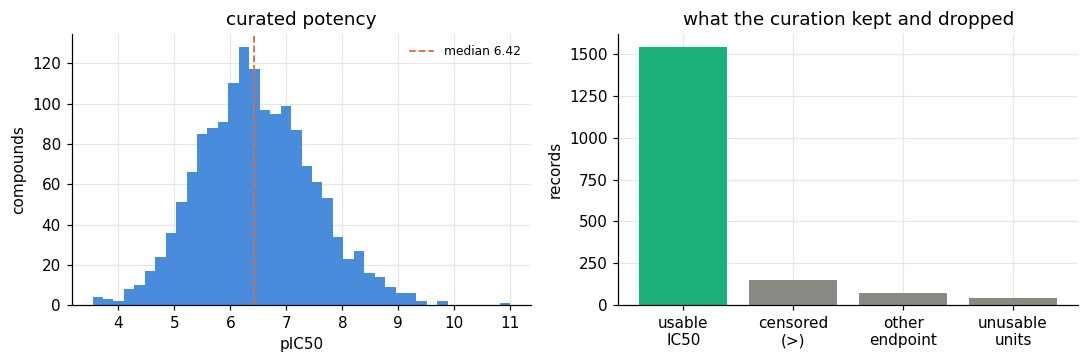

In [15]:
activity = curate_activity(raw)
N_CURATED = len(activity)
print(f"{N_RECORDS:,} records -> {N_CURATED:,} compounds · "
      f"{int((activity.n_measurements > 1).sum())} measured more than once")
display(activity.sort_values("pIC50", ascending=False).head(5).round(2))

# the same records without the aggregation, to see where a compound's replicates disagree
_sp = record_level_pIC50(raw).groupby("canonical_smiles").pIC50_record.agg(["count", "min", "max"])
_sp["range"] = (_sp["max"] - _sp["min"]).round(2)
print(f"\ncompounds whose replicates disagree by more than 2 log units: {(_sp.range > 2).sum()}")
display(_sp[_sp.range > 2].sort_values("range", ascending=False).head(6).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(activity.pIC50, bins=40, color=BLUE, alpha=.85)
axes[0].axvline(activity.pIC50.median(), color=ORANGE, lw=1.2, ls="--",
                label=f"median {activity.pIC50.median():.2f}")
axes[0].set(title="curated potency", xlabel="pIC50", ylabel="compounds"); axes[0].legend(frameon=False, fontsize=8)
_cens = raw[raw.standard_relation == ">"]
axes[1].bar(["usable\nIC50", "censored\n(>)", "other\nendpoint", "unusable\nunits"],
            [N_CURATED, len(_cens),
             int((raw.standard_type != "IC50").sum()),
             int((~raw.standard_units.isin(["nM", "uM", "M"])).sum())],
            color=[AQUA, GREY, GREY, GREY])
axes[1].set(title="what the curation kept and dropped", ylabel="records")
plt.tight_layout(); plt.show()

**Q1** (a) Which curation rule removed the most records, and by how many log units can skipping the unit conversion move a single label? (b) Look at the replicates that disagree by more than two log units: is that an assay problem or a bookkeeping problem, and how can you tell? (c) The censored `>` records were dropped. They carry real information — the compound is weak. What goes wrong if you instead record them as pIC50 = 5 and fit a regression on them?

⭐ Pull a real target from ChEMBL (`%pip install chembl_webresource_client`) and run your `curate_activity` on it. Report how many records survive and what broke that this simulation does not contain.

*Your answer:*

(a) Regra que removeu mais registos e impacto de ignorar unidades:
- A regra individual que removeu mais registos foi a remoção de medições censuradas (standard_relation == ">"), que eliminou 150 registos (em comparação com 70 de outros endpoints: 38 Ki + 32 EC50; 44 de unidades inutilizáveis: 25 % + 19 ug.mL-1; e 15 de SMILES inválidos). Além disso, a agregação de replicados após remover sais condensou os restantes registos até 1,541 compostos únicos (321 medidos mais de uma vez).
- Ignorar a conversão de unidades desloca um rótulo de pIC50 em 3 unidades logarítmicas quando se confunde $\mu\text{M}$ com $\text{nM}$ ($1\,\mu\text{M} = 10^3\,\text{nM} \Rightarrow \Delta\text{pIC}_{50} = 3$) e em 9 unidades logarítmicas quando se confunde $\text{M}$ com $\text{nM}$ ($1\,\text{M} = 10^9\,\text{nM} \Rightarrow \Delta\text{pIC}_{50} = 9$).   

(b) Replicados que discordam em > 2 unidades log (42 compostos):
- Trata-se de um problema de registo/unidades (bookkeeping problem) e não de ruído experimental do ensaio.
- Como se vê: Na tabela dos compostos com maior discrepância (range de 3.20, 3.16, 3.14, 3.11, 3.09, 3.07), a diferença entre o mínimo e o máximo agrupa-se sistematicamente à volta de 3.0 unidades logarítmicas (um fator exato de $1000\times$). O ruído normal de ensaio varia tipicamente entre $0.1$ e $0.5$ unidades log; um salto sistemático de $\approx 3$ unidades log é a assinatura clássica de um erro de transcrição entre $\text{nM}$ e $\mu\text{M}$.   

(c) O que corre mal ao codificar censurados (> 10,000 nM) como pIC50 = 5 numa regressão:
- Um registo > 10,000 nM apenas garante que $\text{pIC}_{50} < 5$ (o valor real pode ser 4, 3 ou completamente inativo).
- Se fixarmos todos esses compostos em pIC50 = 5.0, introduzimos viés sistemático de censura: sobrestimamos a potência dos compostos fracos/inativos, criamos uma acumulação artificial de rótulos em 5.0 e distorcemos a função de perda (erro quadrático), o que achata o declive das previsões do modelo e degrada o $R^2$ e a capacidade de distinguir moléculas moderadas de verdadeiramente inativas. (A forma correta de usar dados censurados seria classificação binária com limiar ou modelos de regressão censurada/Tobit.)

---
## Part 2 · QSAR: the split decides what the number means

Same compounds, now with a model. Three representations of the same molecule, two ways of splitting the same data.

> **Biology** · A medicinal chemistry series is built by decorating a few core structures. Compounds that share a core share most of their behaviour, so two analogues are not two independent observations — which is exactly what a random split assumes they are. The Bemis–Murcko scaffold is that core: strip the side chains, keep the ring systems and the linkers between them.

> **Code** · ECFP4 counts circular atom environments into 2,048 bits; the descriptors are twelve physicochemical numbers; a chemical language model is a transformer pretrained on tens of millions of SMILES. Same forest, same target, same split — only the input changes.

1,541 compounds · 198 distinct scaffolds · largest series 106 compounds · 69 scaffolds seen once


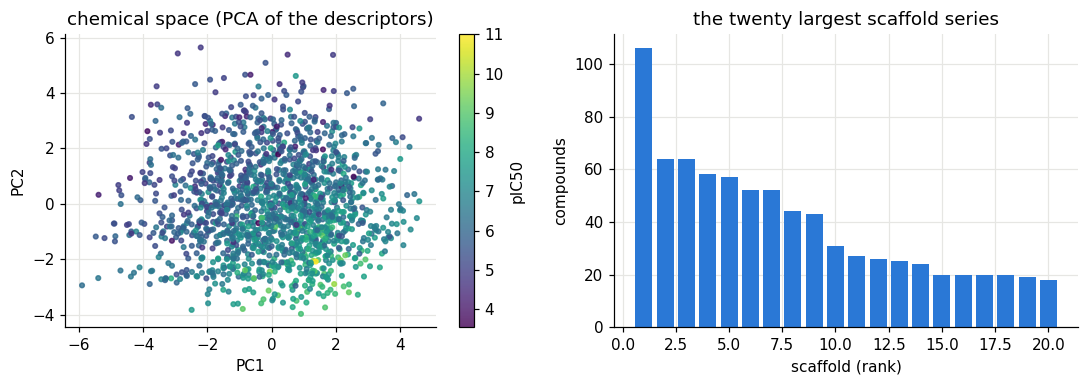

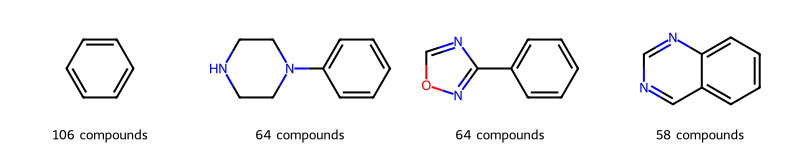

In [16]:
smiles = list(activity.index)
y = activity.pIC50.to_numpy()
X_fp = ecfp4(smiles)
X_desc = descriptors(smiles)
scaffolds = pd.Series([murcko_scaffold(s) for s in smiles], index=smiles)
N_SCAFFOLDS = int(scaffolds.nunique())
sizes = scaffolds.value_counts()
print(f"{len(smiles):,} compounds · {N_SCAFFOLDS} distinct scaffolds · "
      f"largest series {sizes.iloc[0]} compounds · {int((sizes == 1).sum())} scaffolds seen once")

_pc = PCA(2).fit_transform(StandardScaler().fit_transform(X_desc))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sc = axes[0].scatter(_pc[:, 0], _pc[:, 1], c=y, cmap="viridis", s=9, alpha=.8)
plt.colorbar(sc, ax=axes[0], label="pIC50")
axes[0].set(title="chemical space (PCA of the descriptors)", xlabel="PC1", ylabel="PC2")
axes[1].bar(range(1, 21), sizes.iloc[:20].to_numpy(), color=BLUE)
axes[1].set(title="the twenty largest scaffold series", xlabel="scaffold (rank)", ylabel="compounds")
plt.tight_layout(); plt.show()
display(grid(list(sizes.index[:4]), [f"{n} compounds" for n in sizes.iloc[:4]], per_row=4, size=(200, 150)))

### Task B · `scaffold_split`
A split in which no scaffold appears on both sides. Group the molecules by `murcko_scaffold`; order the groups by size, largest first, ties broken by the scaffold SMILES; fill the training side with whole groups until it holds `round((1 − test_fraction) * n)` molecules; everything after that goes to test. Return two arrays of indices, each sorted ascending.

<details><summary>Hint</summary>

Build `{scaffold: [indices]}` with `setdefault`. Then `sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0]))` gives the order; walk it and extend whichever list is still being filled. The test side ends up holding the many small series — which is the honest situation: new chemistry arrives as singletons, not as analogues of what you already have.
</details>

In [17]:
def scaffold_split(smiles, test_fraction=0.25):
    """smiles: a list of SMILES. Return (train_idx, test_idx), arrays of positions into that list, sorted
    ascending, such that no Bemis-Murcko scaffold appears on both sides.
    """
    # Group indices by Bemis-Murcko scaffold
    groups = {}
    for i, s in enumerate(smiles):
        scaf = murcko_scaffold(s)
        groups.setdefault(scaf, []).append(i)

    # Sort groups by size descending, break ties with scaffold SMILES ascending
    sorted_groups = sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0] if kv[0] is not None else ""))

    n_total = len(smiles)
    n_train_target = int(round((1 - test_fraction) * n_total))

    train_idx = []
    test_idx = []

    # Walk and fill the training list first until we reach the target size
    for _, idx_list in sorted_groups:
        if len(train_idx) < n_train_target:
            train_idx.extend(idx_list)
        else:
            test_idx.extend(idx_list)

    return np.array(sorted(train_idx)), np.array(sorted(test_idx))

check_task("B")

[OK] Task B · scaffold_split


random split: 1156 train / 385 test · scaffold split: 1162 train / 379 test
scaffolds shared between the two sides -- random: 105, scaffold: 0


,R2 random,MAE random,R2 scaffold,MAE scaffold,R2 lost
ECFP4 (2048 bits),0.721,0.413,-0.063,0.724,0.784
RDKit descriptors (12),0.537,0.544,0.207,0.613,0.330


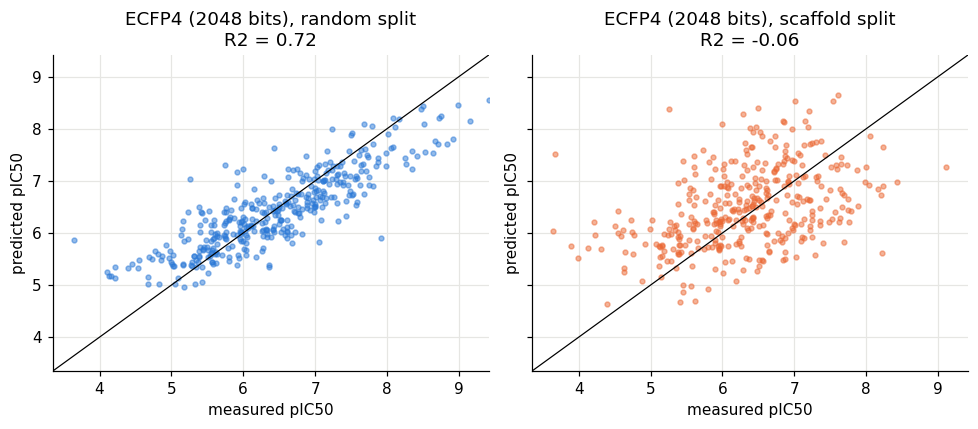

In [18]:
USE_CLM = False         # set to True to add the chemical language model row (downloads ~150 MB; see the Q2 star)

tr_rand, te_rand = random_split(len(smiles), 0.25, seed=0)
tr_scaf, te_scaf = scaffold_split(smiles, 0.25)
print(f"random split: {len(tr_rand)} train / {len(te_rand)} test · "
      f"scaffold split: {len(tr_scaf)} train / {len(te_scaf)} test")
print(f"scaffolds shared between the two sides -- random: "
      f"{len(set(scaffolds.iloc[tr_rand]) & set(scaffolds.iloc[te_rand]))}, "
      f"scaffold: {len(set(scaffolds.iloc[tr_scaf]) & set(scaffolds.iloc[te_scaf]))}")

REPS = {"ECFP4 (2048 bits)": X_fp, "RDKit descriptors (12)": X_desc.to_numpy()}
if USE_CLM:
    print("\nembedding the molecules with a pretrained chemical language model ...")
    _emb = embed_clm(smiles)
    if _emb is not None:
        REPS[f"ChemBERTa embedding ({_emb.shape[1]})"] = _emb

_pred = {}
rows = {}
for _name, _X in REPS.items():
    r = {}
    for _split, (_a, _b) in [("random", (tr_rand, te_rand)), ("scaffold", (tr_scaf, te_scaf))]:
        p = fit_qsar(_X[_a], y[_a]).predict(_X[_b])
        _pred[(_name, _split)] = (y[_b], p)
        r[f"R2 {_split}"], r[f"MAE {_split}"] = r2_score(y[_b], p), mean_absolute_error(y[_b], p)
    r["R2 lost"] = r["R2 random"] - r["R2 scaffold"]
    rows[_name] = r
REPR = pd.DataFrame(rows).T.round(3)
display(REPR)

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, split in zip(axes, ["random", "scaffold"]):
    yt, p = _pred[(list(REPS)[0], split)]
    ax.scatter(yt, p, s=10, alpha=.5, color=BLUE if split == "random" else ORANGE)
    lims = [min(yt.min(), p.min()) - .3, max(yt.max(), p.max()) + .3]
    ax.plot(lims, lims, color="black", lw=.8)
    ax.set(title=f"{list(REPS)[0]}, {split} split\nR2 = {r2_score(yt, p):.2f}",
           xlabel="measured pIC50", ylabel="predicted pIC50", xlim=lims, ylim=lims)
plt.tight_layout(); plt.show()

**Q2** (a) Report both R² for each representation. Which number would you put in a paper, and which one tells you whether the model is worth using on a compound you have not made yet? (b) The ranking of the representations changes between the two splits. What has the best random-split model actually learned? (c) Is a model with the lower scaffold-split R² useless, or is there a job it still does well? Name the job, and say what the applicability domain of this model is.

⭐ Set `USE_CLM = True` to add a pretrained chemical language model as a third representation, and say whether the extra 384 dimensions buy anything on either split. ⭐ Or repeat with a time split: sort by `compound_id` (a proxy for registration order), train on the first 75 %, test on the last 25 %. Which split is closest to how the model would really be used?

*Your answer:*

(a) Report both $R^2$ for each representation. Which number would you put in a paper, and which one tells you whether the model is worth using on a compound you have not made yet?
- Reported $R^2$: ECFP4 achieves $R^2_{\text{random}} = \mathbf{0.721}$ vs. $R^2_{\text{scaffold}} = \mathbf{-0.063}$; RDKit descriptors achieve $R^2_{\text{random}} = \mathbf{0.537}$ vs. $R^2_{\text{scaffold}} = \mathbf{0.207}$.
- Which to publish: In a paper, you should report both (with the scaffold split as the primary generalization metric and the random split only as an in-series benchmark), because reporting only the random split misleads readers into thinking the model generalizes to novel chemistry.
- Which tells you if it works on an unmade compound: The scaffold-split $R^2$ tells you whether the model is worth using on a new chemical series (novel scaffold); the random-split $R^2$ only reflects performance on an unmade analogue of a series already in your training set.

(b) The ranking of the representations changes between the two splits. What has the best random-split model actually learned?  
- On the random split, ECFP4 wins (0.721 vs. 0.537), but on the scaffold split it collapses completely (-0.063, worse than predicting the mean) while RDKit descriptors retain positive predictive power (0.207).   
- What ECFP4 actually learned: Because 105 scaffolds appear in both train and test on the random split, the ECFP4 Random Forest mostly memorized series-specific substructure bits (scaffold identity and R-group lookup) rather than generalizable binding physics. When confronted with unseen scaffolds, those core bits disappear and the model fails. By contrast, the 12 continuous physicochemical descriptors (MolLogP, TPSA, HeavyAtoms, AromaticRings, etc.) capture transferable global SAR trends that still hold across different core structures.

(c) Is a model with the lower scaffold-split $R^2$ useless, or is there a job it still does well? Name the job, and say what the applicability domain of this model is.   
- No, it is not useless. The ECFP4 model (random-split $R^2 = 0.721$, $\text{MAE} = 0.413$ log units) is still very effective for lead optimization / R-group (substituent) prioritization within an existing chemical series—predicting which side-chain modifications will improve potency on a core the project is already synthesizing.  
- Applicability domain: Its applicability domain is restricted to close structural analogues of the training set—specifically compounds sharing one of the training Bemis–Murcko scaffolds (or having high Tanimoto fingerprint similarity to training molecules). Outside that domain (scaffold hopping / novel cores), its predictions are unreliable.

---
## Part 3 · Binding: ranking, or affinity?

`screen_library.csv`: 995 purchasable compounds, with the docking score already computed for each (kcal/mol, more negative is better). Forty-five are known actives from the literature, spiked in so you can measure whether the protocol finds them; `is_active` marks them. The protocol was validated first by re-docking the co-crystallised ligand: RMSD 1.4 Å, so it passes the usual 2 Å gate.

`cofold_predictions.csv`: the eighty best compounds by docking score were then passed to a co-folding model, which predicts the complex and a binding affinity in one shot. **These predictions are simulated** for this assignment; the ⭐ runs the real thing.

> **Biology** · Three ways of asking the same question, and they do not see the same thing. A ligand-based model knows what past actives looked like. Docking knows the shape of the pocket. Co-folding models the complex. Part of binding depends on three-dimensional complementarity that no two-dimensional fingerprint can represent.

> **Code** · A screen does not need correct affinities, it needs the actives near the top. The enrichment factor measures exactly that: how many more actives are in the top slice than chance would put there. Read EF@5% as the headline — the top 1 % is only ten compounds, so EF@1% can only move in steps of 2.2.

In [19]:
screen = pd.read_csv(DATA_DIR / "screen_library.csv")
cofold = pd.read_csv(DATA_DIR / "cofold_predictions.csv")
print(f"{len(screen):,} compounds · {int(screen.is_active.sum())} known actives "
      f"({screen.is_active.mean():.1%}) · co-folding run on {len(cofold)}")

qsar = fit_qsar(np.hstack([X_fp, X_desc.to_numpy()]), y)      # the ligand-based model, on all curated data
featurise = lambda ss: np.hstack([ecfp4(ss), descriptors(ss).to_numpy()])
screen["qsar_pIC50"] = qsar.predict(featurise(screen.smiles)).round(3)
screen_desc = descriptors(screen.smiles)
display(screen.head(4))

995 compounds · 45 known actives (4.5%) · co-folding run on 80


,compound_id,smiles,source,is_active,docking_score,qsar_pIC50
0,ZID00918,O=C(Nc1ccccc1CC1CCCO1)Nc1ccccc1[N+](=O)[O-],catalogue,0,-4.05,6.942
1,ZID00639,O=C(NC1CCNCC1)c1cc2c(N3CCOCC3)cccc2[nH]1,catalogue,0,-6.50,5.507
2,ZID00133,CCCNC(=O)c1ccccc1C(N)=O,catalogue,0,-4.87,5.696
3,ZID00552,O=C(NCC1CCCO1)c1ccc2ccccc2c1N1CCOCC1,catalogue,0,-4.88,6.229


### Task C · `enrichment_factor`
Rank the library by a score, take the top `fraction`, and compare the share of actives there with the share in the whole library. `EF = (hits in top / size of top) / (all actives / N)`, with the size of the top slice `ceil(fraction * N)`. Lower scores rank first by default, as for a docking score; `higher_is_better=True` for a predicted potency.

In [20]:
def enrichment_factor(scores, is_active, fraction=0.01, higher_is_better=False):
    """scores: one value per compound; is_active: 0/1 or boolean. Rank the compounds (lowest score first unless
    higher_is_better), take the top ceil(fraction * N), and return the enrichment factor as a float.
    """
    scores = np.asarray(scores, float)
    is_active = np.asarray(is_active).astype(int)
    N = len(scores)

    # Determine the number of top compounds to slice
    k = int(np.ceil(fraction * N))

    # Sort the indices based on scores
    if higher_is_better:
        order = np.argsort(-scores, kind="stable")
    else:
        order = np.argsort(scores, kind="stable")

    top_indices = order[:k]

    # Calculate hit rate in the top slice
    hits_in_top = is_active[top_indices].sum()
    hit_rate_top = hits_in_top / k

    # Calculate baseline hit rate in the library
    total_actives = is_active.sum()
    hit_rate_library = total_actives / N

    return float(hit_rate_top / hit_rate_library)

check_task("C")

[OK] Task C · enrichment_factor


,EF@1%,EF@5%,EF@10%,ROC AUC
docking score,6.63,5.75,4.64,0.85
QSAR predicted pIC50,8.84,3.54,3.54,0.79
molecular weight,0.00,0.88,1.55,0.65


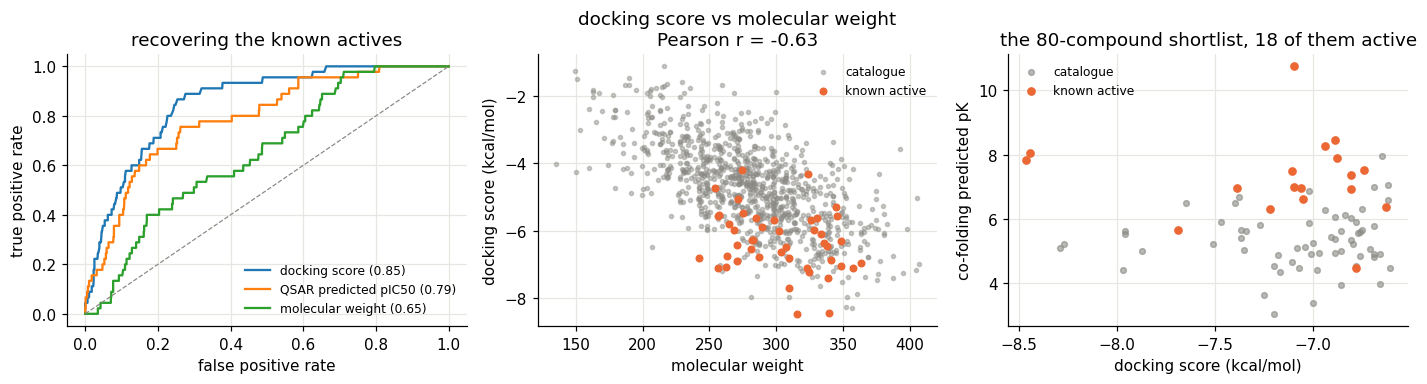

,ROC AUC on the shortlist,Spearman vs co-folding,"Spearman, actives only"
docking score,0.560,0.003,0.116
co-folding affinity,0.904,1.000,1.000
QSAR predicted pIC50,0.692,0.129,0.059


In [ ]:
METHODS = {"docking score": (screen.docking_score.to_numpy(), False),
           "QSAR predicted pIC50": (screen.qsar_pIC50.to_numpy(), True),
           "molecular weight": (screen_desc.MolWt.to_numpy(), True)}      # a control: size alone
SCREEN = pd.DataFrame({
    m: {**{f"EF@{int(f * 100)}%": enrichment_factor(s, screen.is_active, f, hib) for f in [.01, .05, .10]},
        "ROC AUC": roc_auc_score(screen.is_active, s if hib else -s)}
    for m, (s, hib) in METHODS.items()}).T.round(2)
display(SCREEN)

_act = screen.is_active.to_numpy().astype(bool)
_mw = screen_desc.MolWt.to_numpy()
_dock = screen.docking_score.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for m, (s, hib) in METHODS.items():
    fpr, tpr, _ = roc_curve(screen.is_active, s if hib else -s)
    axes[0].plot(fpr, tpr, label=f"{m} ({roc_auc_score(screen.is_active, s if hib else -s):.2f})")
axes[0].plot([0, 1], [0, 1], color=GREY, lw=.8, ls="--")
axes[0].set(title="recovering the known actives", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(frameon=False, fontsize=8)
axes[1].scatter(_mw[~_act], _dock[~_act], s=7, color=GREY, alpha=.45, label="catalogue")
axes[1].scatter(_mw[_act], _dock[_act], s=18, color=ORANGE, label="known active")
_r = np.corrcoef(_mw, _dock)[0, 1]
axes[1].set(title=f"docking score vs molecular weight\nPearson r = {_r:.2f}",
            xlabel="molecular weight", ylabel="docking score (kcal/mol)")
axes[1].legend(frameon=False, fontsize=8)
m = screen.merge(cofold, on=["compound_id", "smiles"])
_mact, _mcat = m[m.is_active == 1], m[m.is_active == 0]
_sp = lambda v, sub: stats.spearmanr(v[sub], m.pred_pK_cofold[sub]).statistic
_all, _act = m.index == m.index, (m.is_active == 1).to_numpy()
COFOLD = pd.DataFrame({
    "docking score": {"ROC AUC on the shortlist": roc_auc_score(m.is_active, -m.docking_score),
                      "Spearman vs co-folding": _sp(-m.docking_score, _all),
                      "Spearman, actives only": _sp(-m.docking_score, _act)},
    "co-folding affinity": {"ROC AUC on the shortlist": roc_auc_score(m.is_active, m.pred_pK_cofold),
                            "Spearman vs co-folding": 1.0, "Spearman, actives only": 1.0},
    "QSAR predicted pIC50": {"ROC AUC on the shortlist": roc_auc_score(m.is_active, m.qsar_pIC50),
                             "Spearman vs co-folding": _sp(m.qsar_pIC50, _all),
                             "Spearman, actives only": _sp(m.qsar_pIC50, _act)}}).T.round(3)
axes[2].scatter(_mcat.docking_score, _mcat.pred_pK_cofold, s=14, color=GREY, alpha=.6, label="catalogue")
axes[2].scatter(_mact.docking_score, _mact.pred_pK_cofold, s=22, color=ORANGE, label="known active")
axes[2].set(title=f"the {len(m)}-compound shortlist, {int(m.is_active.sum())} of them active",
            xlabel="docking score (kcal/mol)", ylabel="co-folding predicted pK")
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
display(COFOLD)

**Q3** (a) The docking score enriches the library but barely ranks the actives among themselves. Using your EF@5% and the Spearman row of the second table, say what the score is fit for and what it is not. (b) Compare the molecular-weight control with the docking row at EF@5%, and look at the middle panel: how much of the enrichment could a reviewer attribute to size rather than to binding? What would you add to the screen to rule that out? (c) The co-folding ROC AUC is measured on the eighty compounds that docking already liked. Why is that number not comparable with the docking AUC on the full library, and which of the two overstates its method?

⭐ Run the real thing: `%pip install boltz` and predict the complex and affinity for your top three compounds on a GPU runtime. Published benchmarks put co-folding affinity at Pearson ≈ 0.6 against physics-based free energy methods, with ranking inside a congeneric series clearly worse than its classification of binder versus non-binder. Compare against your simulated column and say which conclusions of this part survive.

*Your answer:*

(a) Using your EF@5% and the Spearman row of the second table, say what the docking score is fit for and what it is not.  
- What docking is fit for: Coarse primary virtual screening (library triage / filtering). An EF@5% = 5.75 (and full-library ROC AUC = 0.85) means docking places nearly 6 times more actives in the top 5% than random selection, efficiently cutting a large library down to an enriched shortlist (capturing 18 of 45 actives in just 80 compounds).   
- What docking is NOT fit for: Fine-grained potency ranking or hit-to-lead prioritization among top hits. On the 80-compound shortlist, docking's ROC AUC collapses to 0.560 (near random), and its Spearman rank correlation with co-folding affinity is 0.003 overall and 0.116 among actives only—meaning once obvious non-binders are removed, docking cannot distinguish stronger binders from weaker ones.

(b) Compare the molecular-weight control with the docking row at EF@5%, and look at the middle panel: how much of the enrichment could a reviewer attribute to size rather than to binding? What would you add to the screen to rule that out?   
- How much enrichment is due to size: The middle panel shows a strong negative correlation between docking score and molecular weight (Pearson $r = -0.63$, meaning heavier molecules systematically receive more negative/favorable docking scores), which gives MW alone a global ROC AUC = 0.65. However, at EF@5%, MW alone scores only 0.88 (worse than random = 1.0, and EF@1% = 0.00), compared to docking's 5.75. Therefore, while size bias inflates docking's global AUC, a reviewer cannot attribute the early enrichment (EF@5%) to molecular weight alone—real pocket complementarity is driving the top-5% hits.   
- What to add to rule out size bias:
1. Score by Ligand Efficiency ($\text{LE} = -\text{docking\_score} / N_{\text{heavy}}$) instead of raw kcal/mol to normalize out additive heavy-atom contributions.
2. Benchmark against property-matched decoys (matching actives in MW, logP, charge, and rotatable bonds) so a size-only control is forced to ROC AUC ≈ 0.50.

(c) Why is the co-folding ROC AUC on the 80-compound shortlist not comparable with the docking AUC on the full library, and which of the two overstates its method?   
- Why they are not comparable: Docking's ROC AUC = 0.85 is computed over the full 995-compound catalogue (4.5% active, filled with easy-to-reject small/non-complementary decoys), whereas co-folding's ROC AUC = 0.904 is computed only on the pre-selected 80-compound docking shortlist (22.5% active, where easy decoys are already gone and the 27 actives missed by docking are excluded). Different sample distributions and base rates make raw AUCs non-comparable.  
- Which overstates its method: Docking's full-library AUC (0.85) overstates its practical ranking power, because much of that score comes from rejecting obvious non-binders and exploiting molecular-weight bias (r = -0.63); on the actual compounds you would consider buying (the 80-compound shortlist), its AUC plunges to 0.560. By contrast, co-folding achieves 0.904 on the hardest subset—though note that it was never tested on the other 915 compounds, so its shortlist AUC reflects its performance as a re-scoring stage inside a two-stage funnel, not a standalone full-library screen.   

---
## Part 4 · ADMET and the molecules you designed

`admet_train.csv`: 900 compounds with two endpoints — aqueous solubility `logS` and `herg_blocker` (cardiac risk). **Simulated** from the usual physicochemical drivers; the ⭐ swaps in real data.

> **Biology** · Most candidates fail after potency is solved, on absorption, distribution, metabolism, excretion and toxicity. A compound that cannot dissolve never reaches the target; one that blocks hERG stops the programme whatever its IC50. Potency is the easy axis to optimise, which is why generative models are good at it and why that is not the test that matters.

> **Code** · Three generators on the same objective. Fragment recombination cannot produce an invalid molecule, so its validity is 100 % by construction and tells you nothing. A text-level generator can, which is what makes validity worth reporting for it. Then the honest question: after the filters, how many are left?

In [22]:
admet = pd.read_csv(DATA_DIR / "admet_train.csv")
_cut = 700
predict_admet = fit_admet(admet.iloc[:_cut])                       # held-out tail for the check below
_held = admet.iloc[_cut:]
_p = predict_admet(_held.smiles)
print(f"ADMET models trained on {_cut} compounds, checked on {len(_held)}:")
print(f"  logS           MAE {mean_absolute_error(_held.logS, _p.logS):.2f} log units")
print(f"  hERG blocker   ROC AUC {roc_auc_score(_held.herg_blocker, _p.p_herg):.2f}")

ADMET models trained on 700 compounds, checked on 200:
  logS           MAE 0.53 log units
  hERG blocker   ROC AUC 0.89


### Three generators, one objective
The objective is the QSAR model from Part 3. Keep in mind what Part 2 told you about where that model is trustworthy.

117 BRICS fragments from the 400 most potent compounds


,molecules,best,median
generation,,,
1,200,7.39,6.06
2,199,9.24,8.18
3,199,9.24,7.75
4,199,9.24,7.76


,n_proposed,validity,uniqueness,novelty,median QED,median SA,median MolWt,median logP
random recombination,400.0,1.000,1.0,1.000,0.546,2.632,387.614,2.589
QSAR-guided GA,198.0,1.000,1.0,1.000,0.429,2.389,372.923,5.712
character-level sampler,300.0,0.103,1.0,0.935,0.810,2.939,285.435,3.090


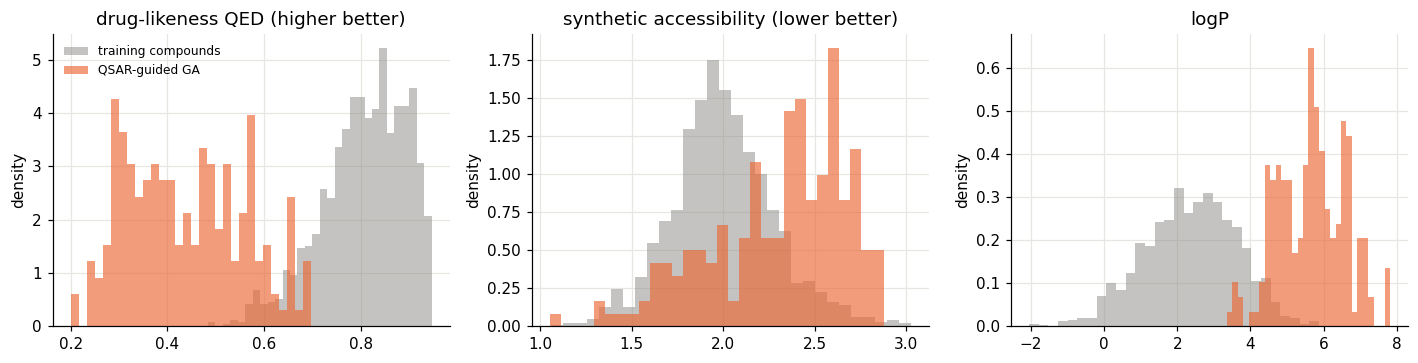

In [23]:
_top = activity.sort_values("pIC50", ascending=False).head(400).index.tolist()
fragments = brics_fragments(_top)
print(f"{len(fragments)} BRICS fragments from the 400 most potent compounds")

random_lib = brics_sample(fragments, 400, seed=1)                                  # recombination, no selection
score_potency = lambda ss: qsar.predict(featurise(ss))                             # the objective: potency alone
ga_lib, ga_history = ga_optimise(random_lib, score_potency, generations=4, population=200, seed=2)
display(pd.DataFrame(ga_history).set_index("generation").round(2))
text_lib = [mutate_smiles(s, 2, seed=i)                                            # edits on the SMILES string
            for i, s in enumerate(np.random.RandomState(0).choice(_top, 300))]

GEN, _kept = {}, {}
for _name, _gen in [("random recombination", random_lib), ("QSAR-guided GA", ga_lib),
                    ("character-level sampler", text_lib)]:
    GEN[_name], _kept[_name] = generation_report(_gen, smiles)
GEN = pd.DataFrame(GEN).T
display(GEN.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, lab in zip(axes, ["QED", "SA", "MolLogP"],
                        ["drug-likeness QED (higher better)", "synthetic accessibility (lower better)", "logP"]):
    ax.hist(descriptors(smiles)[col], bins=30, color=GREY, alpha=.5, density=True, label="training compounds")
    ax.hist(descriptors(_kept["QSAR-guided GA"])[col], bins=30, color=ORANGE, alpha=.65, density=True,
            label="QSAR-guided GA")
    ax.set(title=lab, ylabel="density")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Task D · `admet_cascade`
Chain the filters in order, each applied to whatever survived the one before. `filters` is a list of `(name, column, low, high)`; keep a row when `low <= value <= high`, with `None` meaning unbounded. A missing value fails the filter.

Return `(funnel, kept)`: `funnel` is a DataFrame with one row per filter in order, indexed by the filter name, with columns `n_in`, `n_removed`, `n_out`; `kept` is the index of the survivors.

In [24]:
def admet_cascade(table, filters):
    """table: candidates x properties. filters: list of (name, column, low, high); None means unbounded; a NaN
    value fails the filter. Apply them in order to the survivors of the previous step.
    Return (funnel, kept) as described above.
    """
    kept = table.index.copy()
    rows = []

    for name, col, low, high in filters:
        # Extract values for the currently surviving subset
        v = pd.to_numeric(table.loc[kept, col], errors="coerce")
        n_in = len(kept)

        # Check if the values are non-NaN and fall within the bounds
        ok = v.notna()
        if low is not None:
            ok &= (v >= low)
        if high is not None:
            ok &= (v <= high)

        n_removed = int((~ok).sum())
        n_out = int(ok.sum())

        rows.append((name, n_in, n_removed, n_out))
        kept = kept[ok.to_numpy()]

    funnel = pd.DataFrame(rows, columns=["step", "n_in", "n_removed", "n_out"]).set_index("step")
    return funnel, kept

check_task("D")

[OK] Task D · admet_cascade


,n_in,n_removed,n_out
step,,,
predicted pIC50 >= 6.5,150,0,150
MW <= 500,150,5,145
logP <= 5,145,94,51
HBD <= 5,51,0,51
TPSA >= 40,51,19,32
logS >= -5,32,26,6
hERG risk < 0.5,6,0,6
SA score <= 4,6,0,6
QED >= 0.4,6,0,6


150 designed molecules -> 6 survive the cascade


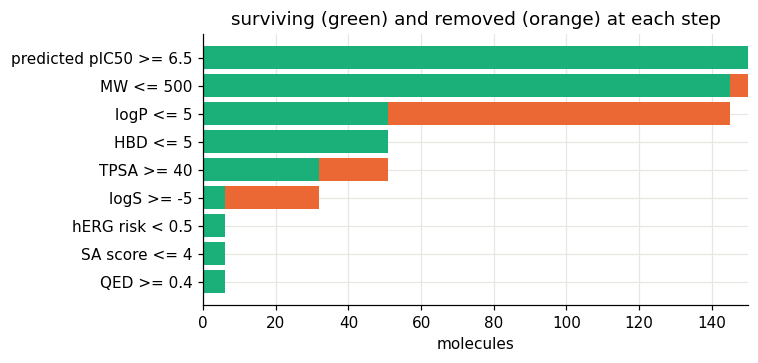

median logP of the designed molecules: 5.49 (training compounds: 2.42) · median QED 0.48 (0.82)


,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,QED,SA,logS,p_herg,qsar_pIC50
N#Cc1cccc2nc(-c3nc4ccccc4[nH]3)ccc12,270.30,3.65,65.36,1.0,3.0,0.57,2.15,-4.77,0.09,7.56
N#Cc1cccc2nc(-c3ncnc4ccccc34)ccc12,282.31,3.72,62.46,0.0,4.0,0.53,2.20,-4.81,0.13,7.50
N#Cc1cccc2nc(-c3nc4c(F)cccc4[nH]3)ccc12,288.29,3.79,65.36,1.0,3.0,0.58,2.34,-4.88,0.17,7.49
N#Cc1cccc2nc(-c3nc4c(C#N)cccc4[nH]3)ccc12,295.30,3.52,89.15,1.0,4.0,0.58,2.51,-4.78,0.14,7.49
N#Cc1cccc2nc(-c3nc4c(O)cccc4[nH]3)ccc12,286.29,3.36,85.59,2.0,4.0,0.56,2.41,-4.56,0.12,7.40
N#Cc1cccc2nc(-c3ncnc4c(C#N)cccc34)ccc12,307.32,3.59,86.25,0.0,5.0,0.54,2.52,-4.86,0.13,7.39


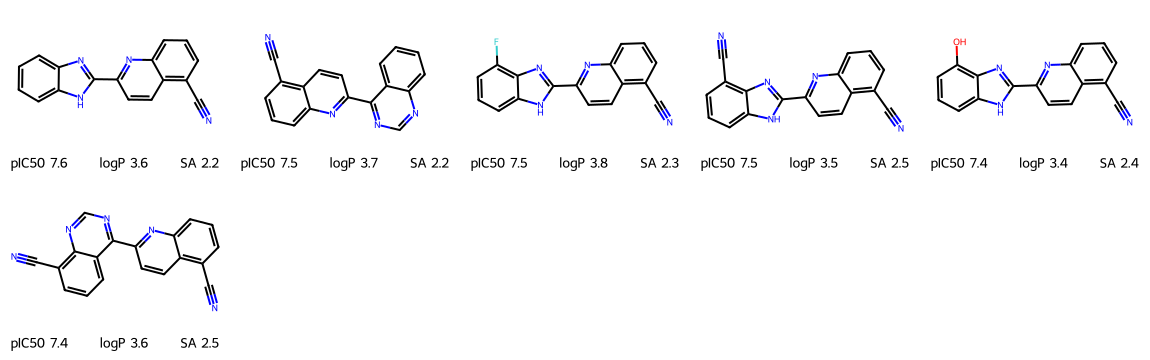

In [25]:
PROPS = ["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "QED", "SA"]


def candidate_table(generated, scorer, n=150):
    """Descriptors, predicted ADMET and predicted potency for the first n distinct molecules."""
    cands = list(dict.fromkeys(generated))[:n]
    t = descriptors(cands)[PROPS].join(predict_admet(cands))
    t["qsar_pIC50"] = np.round(scorer(cands), 3)
    return t


FILTERS = [("predicted pIC50 >= 6.5", "qsar_pIC50", 6.5, None),      # a lead, not yet a candidate
           ("MW <= 500",              "MolWt",      None, 500.0),    # Lipinski
           ("logP <= 5",              "MolLogP",    None, 5.0),
           ("HBD <= 5",               "NumHDonors", None, 5.0),
           ("TPSA >= 40",             "TPSA",       40.0, None),     # a molecule with no polar surface is not a drug
           ("logS >= -5",             "logS",       -5.0, None),     # predicted solubility
           ("hERG risk < 0.5",        "p_herg",     None, 0.5),      # predicted cardiac liability
           ("SA score <= 4",          "SA",         None, 4.0),      # a chemist can make it
           ("QED >= 0.4",             "QED",        0.4, None)]
cand = candidate_table(ga_lib, score_potency)
FUNNEL, kept = admet_cascade(cand, FILTERS)
N_SURVIVORS = len(kept)
display(FUNNEL)
print(f"{len(cand)} designed molecules -> {N_SURVIVORS} survive the cascade")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(range(len(FUNNEL)), FUNNEL.n_out, color=AQUA)
ax.barh(range(len(FUNNEL)), FUNNEL.n_removed, left=FUNNEL.n_out, color=ORANGE)
ax.set(yticks=range(len(FUNNEL)), yticklabels=FUNNEL.index, xlabel="molecules",
       title="surviving (green) and removed (orange) at each step")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

print(f"median logP of the designed molecules: {cand.MolLogP.median():.2f} "
      f"(training compounds: {X_desc.MolLogP.median():.2f}) · median QED {cand.QED.median():.2f} "
      f"({X_desc.QED.median():.2f})")
_final = cand.loc[kept].sort_values("qsar_pIC50", ascending=False).head(10)
if len(_final):
    display(_final.round(2))
    display(grid(list(_final.index), [f"pIC50 {r.qsar_pIC50:.1f} · logP {r.MolLogP:.1f} · SA {r.SA:.1f}"
                                      for _, r in _final.iterrows()]))
else:
    print("nothing survived the cascade. That is a result, not a bug - carry it into Q4.")

### The objective, not the generator

Look at the funnel before going on. The generator did what it was asked: it maximised one number. Everything the
cascade removed was something nobody asked it to keep.

So ask for more. Below, the same algorithm, the same fragments, the same number of generations - with drug-likeness
and lipophilicity written into the score instead of being checked afterwards. This is multi-parameter optimisation,
and the cascade is the referee for both runs.

,molecules,best,median
generation,,,
1,200,10.27,8.71
2,198,10.27,8.64
3,199,10.27,8.34
4,200,10.27,7.67


,median predicted pIC50,median logP,median QED,survive the cascade
potency only,8.31,5.49,0.48,6.0
potency + drug-likeness,7.63,4.05,0.69,19.0


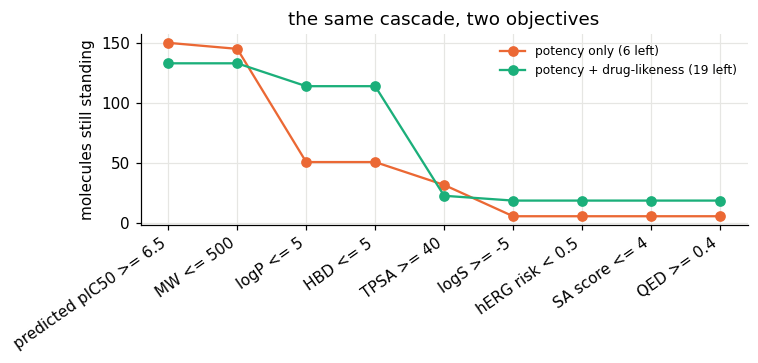

,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,QED,SA,logS,p_herg,qsar_pIC50
CCCc1ncccc1Oc1ccccc1C#N,238.29,3.70,45.91,0.0,3.0,0.82,2.14,-4.43,0.08,7.32
CCCc1ncccc1Oc1ccc(C#N)cc1,238.29,3.70,45.91,0.0,3.0,0.82,2.06,-4.47,0.15,7.29
NS(=O)(=O)c1cccc2c(-c3ccc4c(Cl)cccc4n3)ncnc12,370.82,3.15,98.83,1.0,5.0,0.58,2.44,-4.67,0.10,7.21
NS(=O)(=O)c1cccc2c(Oc3ccc4c(Cl)cccc4n3)ncnc12,386.82,3.27,108.06,1.0,6.0,0.58,2.52,-4.92,0.10,7.17
NS(=O)(=O)c1cccc2c(Oc3ccc4ccccc4c3)ncnc12,351.39,3.22,95.17,1.0,5.0,0.61,2.24,-4.65,0.06,7.15
N#Cc1c(Oc2ncnc3c(S(N)(=O)=O)cccc23)ccc2ccccc12,376.40,3.09,118.96,1.0,6.0,0.59,2.50,-4.66,0.07,7.14
NS(=O)(=O)c1cccc2c(-c3ccc4ccccc4c3)ncnc12,335.39,3.10,85.94,1.0,4.0,0.61,2.19,-4.52,0.07,7.11
NS(=O)(=O)c1cccc2c(Oc3ccc(Cl)cc3)ncnc12,335.77,2.72,95.17,1.0,5.0,0.79,2.20,-4.18,0.09,7.10
NS(=O)(=O)c1cccc2c(Oc3ccc4ccccc4c3F)ncnc12,369.38,3.36,95.17,1.0,5.0,0.60,2.40,-4.77,0.08,7.09
NS(=O)(=O)c1cccc2c(-c3ccc(Cl)cc3)ncnc12,319.77,2.60,85.94,1.0,4.0,0.79,2.15,-4.19,0.08,7.04


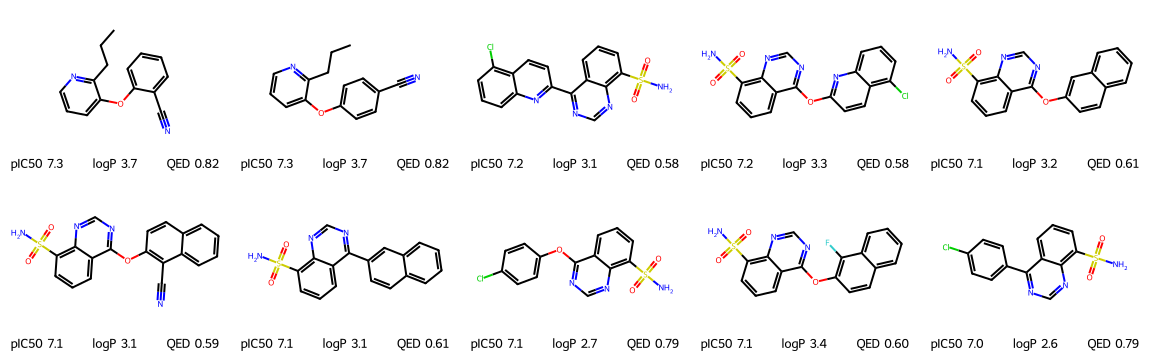

In [26]:
def score_mpo(ss):
    """Potency, rewarded for drug-likeness and penalised above logP 3.5."""
    d = descriptors(ss)
    return score_potency(ss) + 4.0 * d.QED.to_numpy() - np.maximum(0, d.MolLogP.to_numpy() - 3.5)


mpo_lib, mpo_history = ga_optimise(random_lib, score_mpo, generations=4, population=200, seed=2)
display(pd.DataFrame(mpo_history).set_index("generation").round(2))

cand_mpo = candidate_table(mpo_lib, score_potency)
FUNNEL_MPO, kept_mpo = admet_cascade(cand_mpo, FILTERS)
N_SURVIVORS_MPO = len(kept_mpo)

COMPARE = pd.DataFrame({
    "potency only": {"median predicted pIC50": cand.qsar_pIC50.median(), "median logP": cand.MolLogP.median(),
                     "median QED": cand.QED.median(), "survive the cascade": N_SURVIVORS},
    "potency + drug-likeness": {"median predicted pIC50": cand_mpo.qsar_pIC50.median(),
                                "median logP": cand_mpo.MolLogP.median(), "median QED": cand_mpo.QED.median(),
                                "survive the cascade": N_SURVIVORS_MPO}}).T.round(2)
display(COMPARE)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(1, len(FILTERS) + 1), FUNNEL.n_out, "o-", color=ORANGE, label=f"potency only ({N_SURVIVORS} left)")
ax.plot(range(1, len(FILTERS) + 1), FUNNEL_MPO.n_out, "o-", color=AQUA,
        label=f"potency + drug-likeness ({N_SURVIVORS_MPO} left)")
ax.set(xticks=range(1, len(FILTERS) + 1), xticklabels=[f[0] for f in FILTERS], ylabel="molecules still standing",
       title="the same cascade, two objectives")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

_best = cand_mpo.loc[kept_mpo].sort_values("qsar_pIC50", ascending=False).head(10)
if len(_best):
    display(_best.round(2))
    display(grid(list(_best.index), [f"pIC50 {r.qsar_pIC50:.1f} · logP {r.MolLogP:.1f} · QED {r.QED:.2f}"
                                     for _, r in _best.iterrows()]))

**Q4** (a) Validity, uniqueness and novelty come out near perfect for the two fragment generators. Explain why those three numbers were never in danger here, and say what the character-level sampler's validity measures that they cannot. (b) Walk down the first funnel: which filter removed most, and was that a failure of the generator or of the objective you gave it? Then compare the two runs in the table — what did constraining the objective cost in predicted potency, what did it buy in survivors, and which trade would you defend to a project team? (c) Name one feature of the surviving structures that a medicinal chemist would object to and no filter caught, and write the filter you would add. Then: the GA raised its score every generation, scored by the model whose scaffold-split R² you measured in Part 2 — how much of that gain do you believe, and what would settle it?

⭐ Replace the simulated endpoints with real ones (`%pip install PyTDC`, then `Solubility_AqSolDB` and `hERG` from TDC) and rerun both cascades. Report how the survivor counts change and whether the ordering of the two objectives survives.

*Your answer:*

(a) For both fragment generators (random recombination and QSAR-guided GA), all three metrics are 1.000 by design: brics_sample recombines fragments along valid retrosynthetic bonds and runs Chem.SanitizeMol (forcing 100% validity), deduplicates canonical SMILES (forcing 100% uniqueness), and combinatorially assembles 117 fragments into multi-fragment structures that rarely match the single-core training compounds (forcing ~100% novelty). By contrast, the character-level sampler edits raw SMILES text and drops to 0.103 validity (10.3%), measuring whether a sequence model actually understands chemical grammar (balanced parentheses, ring closures, and atom valences), which fragment generators hardcode away.   

(b) Walking down the potency only funnel (150 candidates $\rightarrow$ 6 survivors): MW <= 500 removes 5, logP <= 5 removes 94 (the biggest drop), TPSA >= 40 removes 19, and logS >= -5 removes 26 (all other filters remove 0). This is a failure of the objective, not the generator—the GA simply maximized the QSAR score (Goodhart's Law), exploiting its preference for lipophilicity (median logP jumped from 2.42 in training to 5.49). Constraining the objective (potency + drug-likeness) cost 0.68 log units of median predicted $\text{pIC}_{50}$ (8.31 $\rightarrow$ 7.63), but more than tripled survivors from 6 to 19 while improving median logP (5.49 $\rightarrow$ 4.05) and median QED (0.48 $\rightarrow$ 0.69). I would defend the MPO trade to a project team: a $\text{pIC}_{50}$ of 7.63 ($\approx 23\,\text{nM}$) is already strong lead potency, whereas greasy, insoluble molecules fail downstream regardless of $\text{IC}_{50}$.   

(c) A medicinal chemist would object to the excessive aromaticity / complete flatness ("flatland") of the survivors—all 6 potency-only survivors (e.g., N#Cc1cccc2nc(-c3nc4ccccc4[nH]3)ccc12) and the 3rd MPO survivor have 4 fused/linked aromatic rings and FractionCSP3 = 0.0, which drives poor real-world solubility (their logS sits at -4.56 to -4.88, right on the -5.0 cutoff) and off-target promiscuity. I would add:   Python("AromaticRings <= 3", "AromaticRings", None, 3.0)  # and/or ("Fsp3 >= 0.2", "FractionCSP3", 0.2, None)
I believe very little of the GA's score jump (median 6.06 $\rightarrow$ 7.76, best 9.24): Part 2 showed that ECFP4 collapses on unseen scaffolds ($R^2_{\text{scaffold}} = \mathbf{-0.063}$) and descriptors only reach 0.207, so on 100% novel fragment combinations the GA is mostly exploiting QSAR extrapolation noise. Settling it requires 3D structure-based re-scoring (co-folding / FEP) followed by synthesis and wet-lab $\text{IC}_{50}$ / ADMET assays. 

---
## Closing · the same molecule is not the same dose

Your cascade ends with a molecule. A patient ends with a dose, and the two are not related by a constant.

Take clopidogrel, a prodrug that CYP2C19 has to activate. A patient carrying two loss-of-function alleles (`*2`, `*3`) is a poor metaboliser: the standard dose produces little active drug and leaves them unprotected after a stent, which is why the CPIC guideline recommends an alternative antiplatelet rather than a higher dose. The same reasoning, with different genes, applies to TPMT and thiopurines, DPYD and fluorouracil, HLA-B\*57:01 and abacavir.

Nothing to run here, and nothing graded.

**Q5** Your QSAR, your docking protocol and your ADMET models were all fitted on data where the patient does not appear as a variable. Name one place in this notebook where that assumption is already doing damage, and say what data you would need to fix it. Connect your answer to the population-structure problem from Chapter 2.

*Your answer:*

Where the patient-free assumption is already doing damage in this notebook:
- Part 4's admet_cascade and p_herg (cardiac liability) / ADMET filtering treat safety and exposure as fixed properties of the molecule alone (p_herg < 0.5, logS >= -5). In reality, whether a molecule causes hERG-mediated QT prolongation or fails to work depends on in vivo plasma exposure in a specific patient, which is governed by polymorphic drug-metabolizing enzymes (e.g., CYP2D6, CYP2C19, CYP3A4), drug transporters, and patient-specific susceptibility alleles (e.g., KCNH2/hERG variants or immune HLA alleles). A compound with a "safe" predicted p_herg at standard exposure can become cardiotoxic in a poor metabolizer whose plasma concentration accumulates several-fold—or a prodrug/active compound can be ineffective in an ultra-rapid metabolizer. (The same issue also affects Parts 1–3, where QSAR, docking, and co-folding assume a single wild-type reference enzyme sequence, ignoring patient polymorphisms or somatic resistance mutations in the binding pocket.)   

Data needed to fix it:
- Patient-level pharmacogenomic and pharmacokinetic (PK/PD) clinical data linking compound + dose + patient genotype (star-alleles in metabolizing enzymes like CYP2C19/CYP2D6, HLA types, and target-gene variants) to measured drug exposure ($C_{\max}$, AUC, active-metabolite ratios) and clinical outcomes (efficacy and adverse events such as QTc prolongation), sourced from curated pharmacogenomics knowledgebases (e.g., PharmGKB / ClinPGx) and multi-ancestry clinical biobanks.   

Connection to the population-structure problem from Chapter 2:
- In Chapter 2, we saw that allele frequencies and linkage disequilibrium (LD) blocks differ substantially across human ancestries, causing GWAS and Polygenic Risk Scores trained on European cohorts to lose accuracy when ported to non-European populations.   
- Pharmacogenes exhibit the exact same ancestry-driven frequency differences: for instance, CYP2C19 loss-of-function alleles (2, 3) are far more prevalent in East Asian populations than in Europeans, while CYP2D6 ultra-rapid metabolizer duplications and HLA-B*57:01 frequencies vary sharply across global ancestries. If a drug's dosing, ADMET safety cutoffs (p_herg), and clinical trials are calibrated on a single homogeneous population—or ignore patient genetics altogether—the resulting "standard dose" will systematically under-treat or cause preventable toxicity in underrepresented populations, reproducing Chapter 2's portability failure directly in the clinic.   

---
## Grader and declaration
The grader re-runs the four checks and saves `results/assignment5_<student>.json`. Submit it with the notebook and its outputs.

In [27]:
#@title Grader (run it; do not edit)
rows = [(k, name, *_run(f)) for k, (name, f) in TASKS.items()]
display(pd.DataFrame(rows, columns=["task", "function", "status", "note"]).set_index("task"))
print(f"{sum(r[2] == 'passed' for r in rows)} of {len(rows)} tasks passed")
g = globals().get
num = lambda v: None if v is None or v != v else round(float(v), 4)
tab = lambda t: None if t is None else {str(a): {str(b): num(v) for b, v in r.items()}
                                        for a, r in t.to_dict(orient="index").items()}
record = {"assignment": "CAP5-A5", "student": STUDENT_NUMBER, "attempt": ATTEMPT,
          "tasks": {r[0]: r[2] for r in rows},
          "results": {"n_records": num(g("N_RECORDS")), "n_curated": num(g("N_CURATED")),
                      "n_scaffolds": num(g("N_SCAFFOLDS")), "representations": tab(g("REPR")),
                      "screening": tab(g("SCREEN")), "cofold": tab(g("COFOLD")),
                      "generation": tab(g("GEN")), "cascade": tab(g("FUNNEL")),
                      "cascade_mpo": tab(g("FUNNEL_MPO")), "objectives": tab(g("COMPARE")),
                      "n_survivors": num(g("N_SURVIVORS")), "n_survivors_mpo": num(g("N_SURVIVORS_MPO"))},
          "date_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")}
record["checksum"] = hashlib.sha256(json.dumps(record, sort_keys=True, default=str).encode()).hexdigest()[:16]
path = RESULTS_DIR / f"assignment5_{STUDENT_NUMBER}.json"
path.write_text(json.dumps(record, indent=2, default=str))
print(f"record saved to {path} (code {record['checksum']})")
if IN_COLAB:
    from google.colab import files
    files.download(str(path))

,function,status,note
task,,,
A,curate_activity,passed,
B,scaffold_split,passed,
C,enrichment_factor,passed,
D,admet_cascade,passed,


4 of 4 tasks passed
record saved to results/assignment5_a2023235452.json (code 769ee25a3a627350)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**AI-assistant declaration**: I used AI for producing code, validation of my insights and generating answers with my insights
